# Case Study 1: Exploring Customer Data for a Retail Company


In [13]:
import numpy as np 
import pandas as pd  
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Dataset

df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\customer_data.csv')

<>:1: SyntaxWarning: invalid escape sequence '\B'
<>:1: SyntaxWarning: invalid escape sequence '\B'
C:\Users\Snehal\AppData\Local\Temp\ipykernel_7192\3495808150.py:1: SyntaxWarning: invalid escape sequence '\B'
  df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\customer_data.csv')


In [15]:
df.head(5)

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29


In [16]:
df.tail()

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
95,96,41,Female,Phoenix,2,616.88,2024-10-27
96,97,22,Female,Houston,28,66.42,2024-11-03
97,98,60,Male,Houston,7,4966.48,2024-11-10
98,99,67,Female,Houston,27,3982.74,2024-11-17
99,100,26,Female,Chicago,19,3319.24,2024-11-24


In [ ]:
# Shape

df.shape

(100, 7)

In [ ]:
# Check column

df.columns

Index(['CustomerID', 'Age', 'Gender', 'Location', 'TotalPurchases',
       'TotalAmountSpent', 'LastPurchaseDate'],
      dtype='object')

In [ ]:
# Check Datatypes

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        100 non-null    int64  
 1   Age               100 non-null    int64  
 2   Gender            100 non-null    object 
 3   Location          100 non-null    object 
 4   TotalPurchases    100 non-null    int64  
 5   TotalAmountSpent  100 non-null    float64
 6   LastPurchaseDate  100 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 5.6+ KB


In [ ]:
# Statistical summary

df.describe()

,CustomerID,Age,TotalPurchases,TotalAmountSpent
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,45.090000,16.620000,2494.188400
std,29.011492,15.814643,9.032802,1471.248513
min,1.000000,18.000000,1.000000,57.640000
25%,25.750000,31.000000,9.750000,1112.405000
50%,50.500000,45.500000,15.000000,2626.165000
75%,75.250000,60.000000,26.000000,3812.867500
max,100.000000,70.000000,30.000000,4966.480000


In [ ]:
# Missing Values

df.isnull().sum()

CustomerID          0
Age                 0
Gender              0
Location            0
TotalPurchases      0
TotalAmountSpent    0
LastPurchaseDate    0
dtype: int64

In [ ]:
# Duplicate Records

df.duplicated().sum()

np.int64(0)

Data Cleaning

In [ ]:
# Remove Duplicates

df.drop_duplicates(inplace=True)

In [27]:
# Convert Date Column

df['LastPurchaseDate'] = pd.to_datetime(df['LastPurchaseDate'])

Step 5: Feature Engineering 

In [28]:
# Age Group

bins = [18, 25, 35, 45, 60, 100]

labels = ['18-25',
          '26-35',
          '36-45',
          '46-60',
          '60 +']

df['AgeGroup'] = pd.cut(df['Age'],
                    bins = bins,
                    labels=labels)

In [29]:
df.head

<bound method NDFrame.head of     CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
0            1   68  Female      Houston              24            595.11   
1            2   35    Male      Phoenix              29           2901.57   
2            3   60    Male      Phoenix              19           4109.95   
3            4   63  Female      Chicago              27           2324.75   
4            5   42    Male  Los Angeles              15           1122.67   
..         ...  ...     ...          ...             ...               ...   
95          96   41  Female      Phoenix               2            616.88   
96          97   22  Female      Houston              28             66.42   
97          98   60    Male      Houston               7           4966.48   
98          99   67  Female      Houston              27           3982.74   
99         100   26  Female      Chicago              19           3319.24   

   LastPurchaseDate AgeGroup  
0 

 * Unvariate analysis

 Age Distribution


In [30]:
df['Age'].describe()

count    100.000000
mean      45.090000
std       15.814643
min       18.000000
25%       31.000000
50%       45.500000
75%       60.000000
max       70.000000
Name: Age, dtype: float64

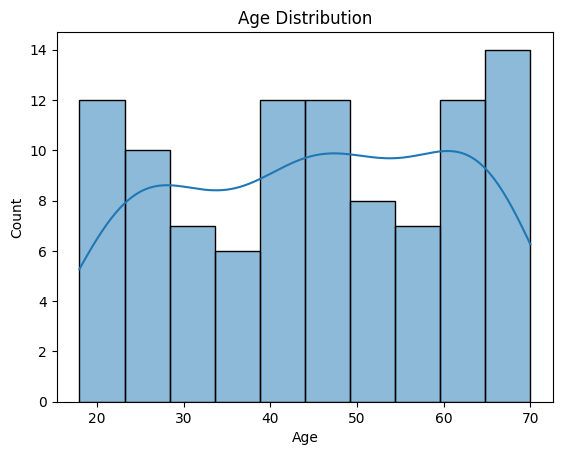

In [31]:
plt.Figure(figsize = (8,5))
sns.histplot(df['Age'], bins=10, kde= True)
plt.title('Age Distribution')
plt.show()

Gender Distribution

In [32]:
df['Gender'].value_counts()

Gender
Female    50
Male      50
Name: count, dtype: int64

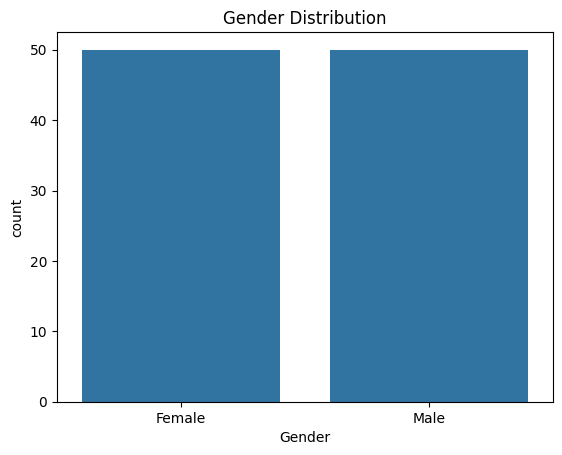

In [33]:
sns.countplot(x='Gender', data=df)
plt.title('Gender Distribution')
plt.show()

Location Distribution

In [34]:
df['Location'].value_counts()


Location
Houston        32
Phoenix        21
Chicago        18
New York       15
Los Angeles    14
Name: count, dtype: int64

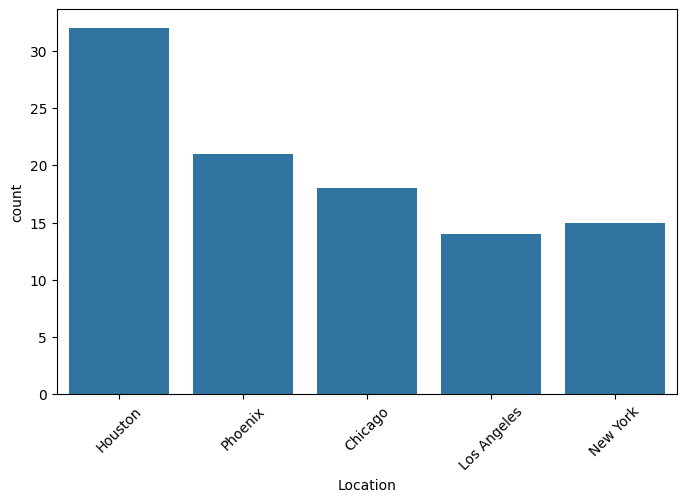

In [35]:
plt.figure(figsize=(8,5))
sns.countplot(x='Location', data=df)
plt.xticks(rotation=45)
plt.show()

Average Spending By Gender

In [36]:
df.groupby('Gender')['TotalAmountSpent'].mean()

Gender
Female    2263.2020
Male      2725.1748
Name: TotalAmountSpent, dtype: float64

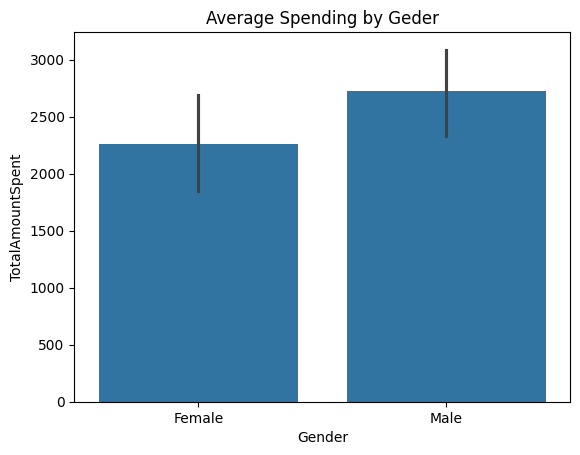

In [37]:
sns.barplot(
    x = 'Gender',
    y = 'TotalAmountSpent',
    data = df
)
plt.title('Average Spending by Geder')
plt.show()

Average Spending by Age Group

In [ ]:
df.groupby('AgeGroup')['TotalAmountSpent'].mean()

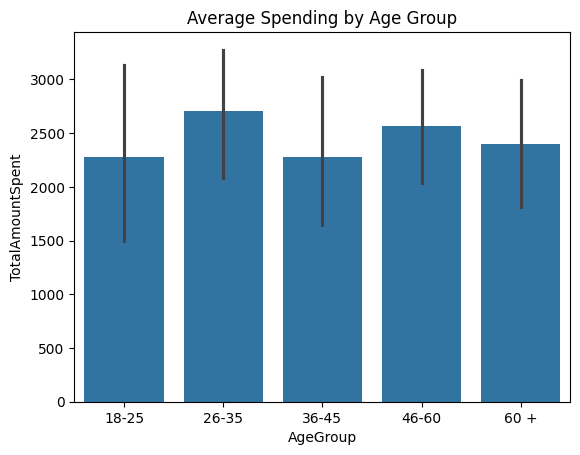

In [39]:
sns.barplot(
    x='AgeGroup',
    y='TotalAmountSpent',
    data=df
)

plt.title('Average Spending by Age Group')
plt.show()

Total Spending by Location

In [40]:
df.groupby('Location')['TotalAmountSpent'].sum().sort_values(ascending=False)


Location
Houston        80502.02
Phoenix        59964.31
Chicago        46500.07
New York       31409.18
Los Angeles    31043.26
Name: TotalAmountSpent, dtype: float64

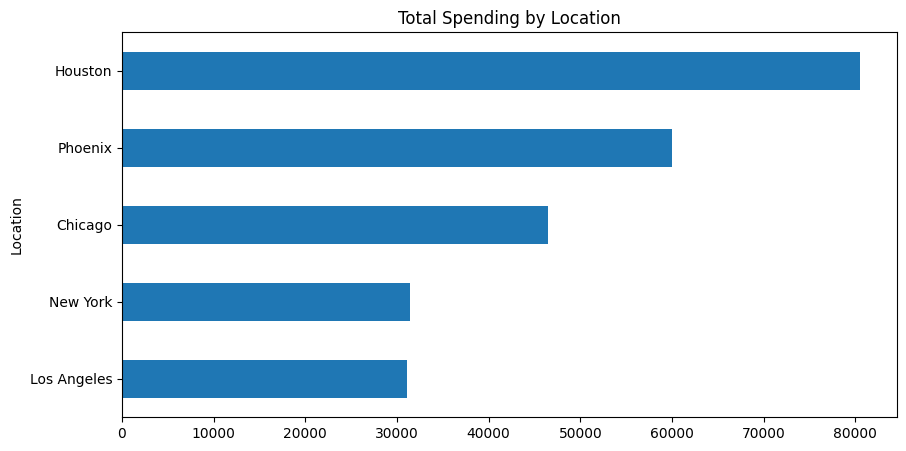

In [41]:
plt.figure(figsize=(10,5))
df.groupby('Location')['TotalAmountSpent'].sum().sort_values().plot(kind='barh')

plt.title('Total Spending by Location')
plt.show()

Average Number of Purchases by Gender

In [42]:
df.groupby('Gender')['TotalPurchases'].mean()


Gender
Female    17.10
Male      16.14
Name: TotalPurchases, dtype: float64

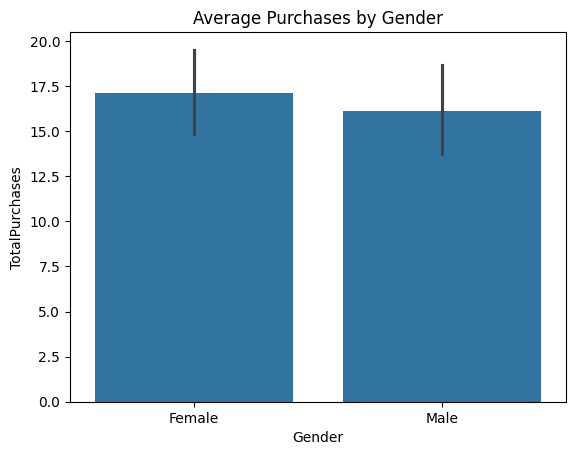

In [43]:
sns.barplot(
    x='Gender',
    y='TotalPurchases',
    data=df
)
plt.title('Average Purchases by Gender')
plt.show()

Customer Lifetime Value

In [ ]:
# Since your dataset already contains the total amount spent 
# The total number of purchases, simple estimate of the average value per purchase is:

df['CLV'] = df['TotalAmountSpent'] / df['TotalPurchases']


In [45]:
df.sort_values(
    by='CLV',
    ascending=False
).head(10) 

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AgeGroup,CLV
32,33,70,Male,Chicago,1,1968.18,2023-08-13,60 +,1968.180000
5,6,56,Female,New York,2,3617.86,2023-02-05,46-60,1808.930000
26,27,65,Female,Houston,1,1670.94,2023-07-02,60 +,1670.940000
21,22,23,Male,New York,3,4083.15,2023-05-28,18-25,1361.050000
37,38,60,Female,Phoenix,2,2405.37,2023-09-17,46-60,1202.685000
38,39,18,Female,Phoenix,5,4947.37,2023-09-24,NaN,989.474000
25,26,54,Male,Houston,2,1428.57,2023-06-25,46-60,714.285000
97,98,60,Male,Houston,7,4966.48,2024-11-10,46-60,709.497143
53,54,68,Male,Houston,6,3991.65,2024-01-07,60 +,665.275000
77,78,53,Female,Los Angeles,1,596.46,2024-06-23,46-60,596.460000


Top 10 Valuable Customers

In [46]:
top10 = df.sort_values(
    by='TotalAmountSpent',
    ascending=False
).head(10)

top10

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AgeGroup,CLV
97,98,60,Male,Houston,7,4966.48,2024-11-10,46-60,709.497143
38,39,18,Female,Phoenix,5,4947.37,2023-09-24,NaN,989.474000
44,45,69,Female,Houston,11,4880.54,2023-11-05,60 +,443.685455
42,43,66,Female,Houston,15,4835.52,2023-10-22,60 +,322.368000
40,41,20,Female,Phoenix,12,4785.73,2023-10-08,18-25,398.810833
78,79,43,Male,Chicago,30,4766.31,2024-06-30,36-45,158.877000
63,64,57,Male,Houston,10,4532.50,2024-03-17,46-60,453.250000
33,34,43,Female,Chicago,28,4467.34,2023-08-20,36-45,159.547857
87,88,49,Female,Houston,9,4380.05,2024-09-01,46-60,486.672222
23,24,31,Male,Los Angeles,8,4302.12,2023-06-11,26-35,537.765000


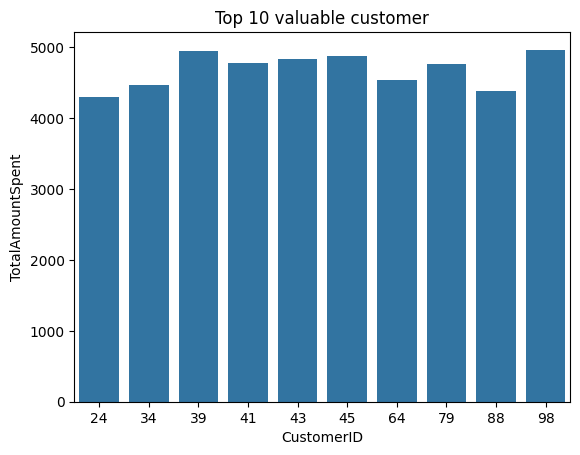

In [48]:
plt.Figure(figsize=(10,5))

sns.barplot(
    x='CustomerID',
    y='TotalAmountSpent',
    data=top10
)
plt.title('Top 10 valuable customer')
plt.show()

Customer Segmentation

In [50]:
df['CustomerSegment'] = pd.qcut(
    df['TotalAmountSpent'],
    q=3,
    labels=['Low','Medium','High']
)
df['CustomerSegment'].value_counts()

CustomerSegment
High      34
Low       33
Medium    33
Name: count, dtype: int64

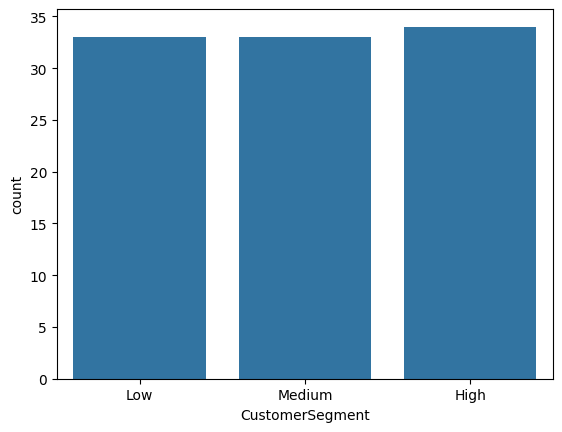

In [51]:
sns.countplot(
    x='CustomerSegment',
    data=df
)
plt.show()

Loyalty Analysis


In [54]:
def loyalty(x):
    if x >= 25:
        return 'VIP'
    elif x>= 15:
        return 'Regular'
    else:
        return 'Occasional'
    
df['Loyalty'] = df['TotalPurchases'].apply(loyalty)

df['Loyalty'].value_counts()

Loyalty
Occasional    46
VIP           29
Regular       25
Name: count, dtype: int64

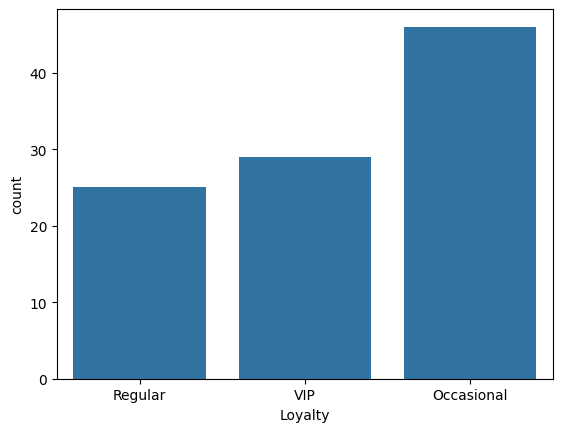

In [ ]:
sns.countplot(
    x='Loyalty',
    data=df
)
plt.show()

correlation

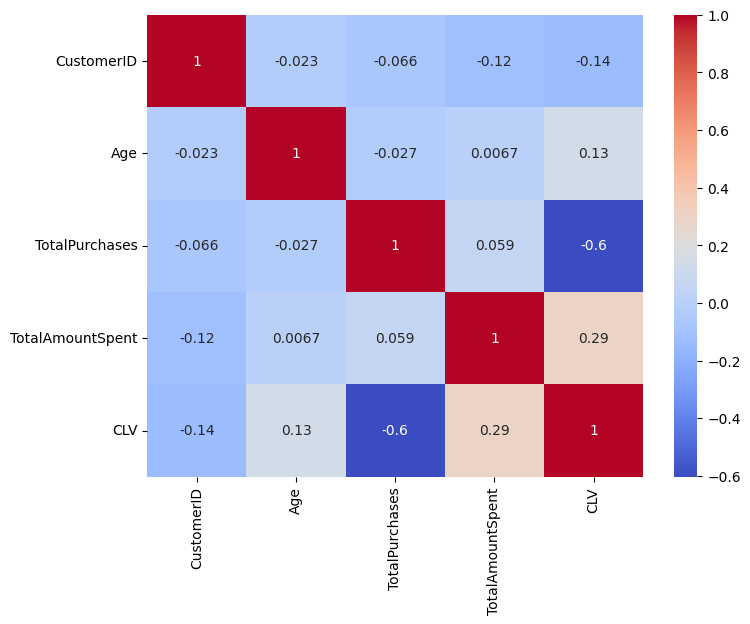

In [59]:
df.corr(numeric_only=True)

plt.figure(figsize=(8,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.show()

Most Valuable Customers

In [60]:
df.sort_values(
    by='TotalAmountSpent',
    ascending=False
).head(10)

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AgeGroup,CLV,CustomerSegment,Loyalty
97,98,60,Male,Houston,7,4966.48,2024-11-10,46-60,709.497143,High,Occasional
38,39,18,Female,Phoenix,5,4947.37,2023-09-24,NaN,989.474000,High,Occasional
44,45,69,Female,Houston,11,4880.54,2023-11-05,60 +,443.685455,High,Occasional
42,43,66,Female,Houston,15,4835.52,2023-10-22,60 +,322.368000,High,Regular
40,41,20,Female,Phoenix,12,4785.73,2023-10-08,18-25,398.810833,High,Occasional
78,79,43,Male,Chicago,30,4766.31,2024-06-30,36-45,158.877000,High,VIP
63,64,57,Male,Houston,10,4532.50,2024-03-17,46-60,453.250000,High,Occasional
33,34,43,Female,Chicago,28,4467.34,2023-08-20,36-45,159.547857,High,VIP
87,88,49,Female,Houston,9,4380.05,2024-09-01,46-60,486.672222,High,Occasional
23,24,31,Male,Los Angeles,8,4302.12,2023-06-11,26-35,537.765000,High,Occasional


Highest Spending Age Group

In [61]:
df.groupby('AgeGroup')['TotalAmountSpent'].agg(['mean','sum','count'])

C:\Users\Snehal\AppData\Local\Temp\ipykernel_7192\534828148.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('AgeGroup')['TotalAmountSpent'].agg(['mean','sum','count'])


,mean,sum,count
AgeGroup,,,
18-25,2279.548462,29634.13,13
26-35,2702.492632,51347.36,19
36-45,2282.241765,38798.11,17
46-60,2563.377586,74337.95,29
60 +,2397.805714,50353.92,21


Highest Spending Location

In [63]:
df.groupby('Location')['TotalAmountSpent'].agg(['mean','sum','count']).sort_values(
    by='sum',
    ascending=False
)

,mean,sum,count
Location,,,
Houston,2515.688125,80502.02,32
Phoenix,2855.443333,59964.31,21
Chicago,2583.337222,46500.07,18
New York,2093.945333,31409.18,15
Los Angeles,2217.375714,31043.26,14


Purchase Behavior by Gender

In [64]:
df.groupby('Gender')[['TotalPurchases','TotalAmountSpent']].mean()

,TotalPurchases,TotalAmountSpent
Gender,,
Female,17.10,2263.2020
Male,16.14,2725.1748
